In [1]:
import torch
import torch.nn as nn
import os
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
import torch.nn.functional as F
from torch.optim import Adam
import matplotlib.pyplot as plt

/local/home/jungao/miniconda3/envs/uvdoc/lib/python3.11/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def activation(name):
    if name in ['tanh', 'Tanh']:
        return nn.Tanh()
    elif name in ['relu', 'ReLU']:
        return nn.ReLU(inplace=True)
    elif name in ['lrelu', 'LReLU']:
        return nn.LeakyReLU(inplace=True)
    elif name in ['sigmoid', 'Sigmoid']:
        return nn.Sigmoid()
    elif name in ['softplus', 'Softplus']:
        return nn.Softplus(beta=4)
    elif name in ['celu', 'CeLU']:
        return nn.CELU()
    elif name in ['elu']:
        return nn.ELU()
    elif name in ['mish']:
        return nn.Mish()
    else:
        raise ValueError('Unknown activation function')

# Spectral (or Fourier) layer in 1d

class SpectralConv1d(nn.Module):
    def __init__(self, in_channels, out_channels, modes1):
        super(SpectralConv1d, self).__init__()

        """
        1D Fourier layer. It does FFT, linear transform, and Inverse FFT.
        """

        self.in_channels = in_channels
        self.out_channels = out_channels
        self.modes1 = modes1

        self.scale = (1 / (in_channels * out_channels))
        self.weights1 = nn.Parameter(self.scale * torch.rand(in_channels, out_channels, self.modes1, dtype=torch.cfloat))

    # Complex multiplication
    def compl_mul1d(self, input, weights):
        # (batch, in_channel, x ), (in_channel, out_channel, x) -> (batch, out_channel, x)
        return torch.einsum("bix,iox->box", input, weights)

    def forward(self, x):
        batchsize = x.shape[0]
        # x.shape == [batch_size, in_channels, number of grid points]
        # hint: use torch.fft library torch.fft.rfft
        # use DFT to approximate the fourier transform

        # Compute Fourier coefficients
        x_ft = torch.fft.rfft(x)

        # Multiply relevant Fourier modes
        out_ft = torch.zeros(batchsize, self.out_channels, x.size(-1) // 2 + 1, device=x.device, dtype=torch.cfloat)
        out_ft[:, :, :self.modes1] = self.compl_mul1d(x_ft[:, :, :self.modes1], self.weights1)

        # Return to physical space
        x = torch.fft.irfft(out_ft, n=x.size(-1))
        return x

class FNO1d(nn.Module):
    def __init__(self, modes, width):
        super(FNO1d, self).__init__()

        """
        The overall network. It contains 4 layers of the Fourier layer.
        1. Lift the input to the desire channel dimension by self.fc0 .
        2. 4 layers of the integral operators u' = (W + K)(u).
            W defined by self.w; K defined by self.conv .
        3. Project from the channel space to the output space by self.fc1 and self.fc2 .

        input: the solution of the initial condition and location (a(x), x)
        input shape: (batchsize, x=s, c=2)
        output: the solution of a later timestep
        output shape: (batchsize, x=s, c=1)
        """

        self.modes1 = modes
        self.width = width
        self.padding = 1  # pad the domain if input is non-periodic
        self.linear_p = nn.Linear(2, self.width)  # input channel is 2: (u0(x), x) --> GRID IS INCLUDED!

        self.spect1 = SpectralConv1d(self.width, self.width, self.modes1)
        self.spect2 = SpectralConv1d(self.width, self.width, self.modes1)
        self.spect3 = SpectralConv1d(self.width, self.width, self.modes1)
        self.lin0 = nn.Conv1d(self.width, self.width, 1)
        self.lin1 = nn.Conv1d(self.width, self.width, 1)
        self.lin2 = nn.Conv1d(self.width, self.width, 1)

        self.linear_q = nn.Linear(self.width, 32)
        self.output_layer = nn.Linear(32, 1)

        self.activation = torch.nn.Tanh()

    def fourier_layer(self, x, spectral_layer, conv_layer):
        return self.activation(spectral_layer(x) + conv_layer(x))

    def linear_layer(self, x, linear_transformation):
        return self.activation(linear_transformation(x))

    def forward(self, x):
        # grid = self.get_grid(x.shape, x.device)
        # x = torch.cat((x, grid), dim=-1)
        x = self.linear_p(x)
        x = x.permute(0, 2, 1)

        # x = F.pad(x, [0, self.padding])  # pad the domain if input is non-periodic

        x = self.fourier_layer(x, self.spect1, self.lin0)
        x = self.fourier_layer(x, self.spect2, self.lin1)
        x = self.fourier_layer(x, self.spect3, self.lin2)

        # x = x[..., :-self.padding]  # pad the domain if input is non-periodic
        x = x.permute(0, 2, 1)

        x = self.linear_layer(x, self.linear_q)
        x = self.output_layer(x)
        return x


In [3]:
def train(mode):
    assert mode in ['gaussian_process', 'piecewise_linear', 'chebyshev']
    u_data = np.load(f"sol_{mode}.npy")
    f_data = np.load(f"f_{mode}.npy")
    u_data = torch.as_tensor(u_data, dtype=torch.float32)
    f_data = torch.as_tensor(f_data, dtype=torch.float32)
    grid = torch.as_tensor(np.linspace(-1,1,51), dtype=torch.float32)
    grid_data = grid.repeat(100,1)
    training_data = torch.stack((f_data,grid_data))
    training_data = training_data.permute(1,2,0)
    training_set = DataLoader(TensorDataset(training_data, u_data), batch_size=10, shuffle=True)
    ##### training params #####
    learning_rate = 0.001
    epochs = 500
    step_size = 50
    gamma = 0.5
    modes = 16
    width = 64
    fno = FNO1d(modes, width) # model
    optimizer = Adam(fno.parameters(), lr=learning_rate, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=step_size, gamma=gamma)

    l = torch.nn.MSELoss()
    freq_print = 1
    training_loss = [1e10]
    for epoch in range(epochs):
        train_mse = 0.0
        for step, (input_batch, output_batch) in enumerate(training_set):
            optimizer.zero_grad()
            output_pred_batch = fno(input_batch).squeeze(2)
            loss_f = l(output_pred_batch, output_batch)
            loss_f.backward()
            optimizer.step()
            train_mse += loss_f.item()
        train_mse /= len(training_set)

        scheduler.step()
        if train_mse < np.min(training_loss):
            torch.save(fno.state_dict(), f"fno_{mode}.pth")
        training_loss.append(train_mse)

        # with torch.no_grad():
        #     fno.eval()
        #     # test_relative_l2 = 0.0
        #     for step, (input_batch, output_batch) in enumerate(testing_set):
        #         output_pred_batch = fno(input_batch).squeeze(2)
        #         loss_f = (torch.mean((output_pred_batch - output_batch) ** 2) / torch.mean(output_batch ** 2)) ** 0.5 * 100
                # test_relative_l2 += loss_f.item()
            # test_relative_l2 /= len(testing_set)

        if epoch % freq_print == 0: print("######### Epoch:", epoch, " ######### Train Loss:", train_mse)#, " ######### Relative L2 Test Norm:", test_relative_l2)
        print(np.min(training_loss))
    return fno


In [4]:
train('gaussian_process')

/local/home/jungao/miniconda3/envs/uvdoc/lib/python3.11/site-packages/torch/autograd/__init__.py:197: UserWarning: CUDA initialization: Unexpected error from cudaGetDeviceCount(). Did you run some cuda functions before calling NumCudaDevices() that might have already set an error? Error 804: forward compatibility was attempted on non supported HW (Triggered internally at ../c10/cuda/CUDAFunctions.cpp:109.)
  Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


######### Epoch: 0  ######### Train Loss: 0.05559734646230936
0.05559734646230936
######### Epoch: 1  ######### Train Loss: 0.021952471183612942
0.021952471183612942


######### Epoch: 2  ######### Train Loss: 0.013004372455179691
0.013004372455179691
######### Epoch: 3  ######### Train Loss: 0.005997580988332629
0.005997580988332629
######### Epoch: 4  ######### Train Loss: 0.004871519492007792
0.004871519492007792
######### Epoch: 5  ######### Train Loss: 0.0037875652313232424
0.0037875652313232424
######### Epoch: 6  ######### Train Loss: 0.0028428761870600283
0.0028428761870600283
######### Epoch: 7  ######### Train Loss: 0.002376634033862501
0.002376634033862501
######### Epoch: 8  ######### Train Loss: 0.003428424149751663
0.002376634033862501
######### Epoch: 9  ######### Train Loss: 0.0025990349240601063
0.002376634033862501
######### Epoch: 10  ######### Train Loss: 0.001609637337969616
0.001609637337969616
######### Epoch: 11  ######### Train Loss: 0.0011645231628790499
0.0011645231628790499
######### Epoch: 12  ######### Train Loss: 0.0013301498867804185
0.0011645231628790499
######### Epoch: 13  ######### Train Loss: 0.0010965853900415823

FNO1d(
  (linear_p): Linear(in_features=2, out_features=64, bias=True)
  (spect1): SpectralConv1d()
  (spect2): SpectralConv1d()
  (spect3): SpectralConv1d()
  (lin0): Conv1d(64, 64, kernel_size=(1,), stride=(1,))
  (lin1): Conv1d(64, 64, kernel_size=(1,), stride=(1,))
  (lin2): Conv1d(64, 64, kernel_size=(1,), stride=(1,))
  (linear_q): Linear(in_features=64, out_features=32, bias=True)
  (output_layer): Linear(in_features=32, out_features=1, bias=True)
  (activation): Tanh()
)

In [5]:
train('piecewise_linear')

######### Epoch: 0  ######### Train Loss: 0.02447553239762783
0.02447553239762783
######### Epoch: 1  ######### Train Loss: 0.004484567340114154
0.004484567340114154
######### Epoch: 2  ######### Train Loss: 0.0010225801597698592
0.0010225801597698592


######### Epoch: 3  ######### Train Loss: 0.0003156160937578534
0.0003156160937578534
######### Epoch: 4  ######### Train Loss: 0.00015946760613587684
0.00015946760613587684
######### Epoch: 5  ######### Train Loss: 5.9950292325083865e-05
5.9950292325083865e-05
######### Epoch: 6  ######### Train Loss: 1.653821332183725e-05
1.653821332183725e-05
######### Epoch: 7  ######### Train Loss: 9.69524874108174e-06
9.69524874108174e-06
######### Epoch: 8  ######### Train Loss: 4.145605862504453e-06
4.145605862504453e-06
######### Epoch: 9  ######### Train Loss: 2.5422169301236865e-06
2.5422169301236865e-06
######### Epoch: 10  ######### Train Loss: 1.6876122572284658e-06
1.6876122572284658e-06
######### Epoch: 11  ######### Train Loss: 1.3366816233428836e-06
1.3366816233428836e-06
######### Epoch: 12  ######### Train Loss: 1.0858961900339637e-06
1.0858961900339637e-06
######### Epoch: 13  ######### Train Loss: 9.404790603184665e-07
9.404790603184665e-07
######### Epoch: 14  ######### Train Los

FNO1d(
  (linear_p): Linear(in_features=2, out_features=64, bias=True)
  (spect1): SpectralConv1d()
  (spect2): SpectralConv1d()
  (spect3): SpectralConv1d()
  (lin0): Conv1d(64, 64, kernel_size=(1,), stride=(1,))
  (lin1): Conv1d(64, 64, kernel_size=(1,), stride=(1,))
  (lin2): Conv1d(64, 64, kernel_size=(1,), stride=(1,))
  (linear_q): Linear(in_features=64, out_features=32, bias=True)
  (output_layer): Linear(in_features=32, out_features=1, bias=True)
  (activation): Tanh()
)

In [6]:
train('chebyshev')

######### Epoch: 0  ######### Train Loss: 0.02247977452352643
0.02247977452352643
######### Epoch: 1  ######### Train Loss: 0.004828502924647182
0.004828502924647182
######### Epoch: 2  ######### Train Loss: 0.0016700283740647137
0.0016700283740647137


######### Epoch: 3  ######### Train Loss: 0.0010672048956621438
0.0010672048956621438
######### Epoch: 4  ######### Train Loss: 0.0006733152345987037
0.0006733152345987037
######### Epoch: 5  ######### Train Loss: 0.0007225434470456094
0.0006733152345987037
######### Epoch: 6  ######### Train Loss: 0.0003507088360493071
0.0003507088360493071
######### Epoch: 7  ######### Train Loss: 0.0002892878925194964
0.0002892878925194964
######### Epoch: 8  ######### Train Loss: 0.00023167566687334328
0.00023167566687334328
######### Epoch: 9  ######### Train Loss: 0.0001877473190688761
0.0001877473190688761
######### Epoch: 10  ######### Train Loss: 0.0001403904301696457
0.0001403904301696457
######### Epoch: 11  ######### Train Loss: 9.716034219309222e-05
9.716034219309222e-05
######### Epoch: 12  ######### Train Loss: 8.712972776265815e-05
8.712972776265815e-05
######### Epoch: 13  ######### Train Loss: 6.447196246881504e-05
6.447196246881504e-05
######### Epoch: 14  ######### Train Loss: 4.740

FNO1d(
  (linear_p): Linear(in_features=2, out_features=64, bias=True)
  (spect1): SpectralConv1d()
  (spect2): SpectralConv1d()
  (spect3): SpectralConv1d()
  (lin0): Conv1d(64, 64, kernel_size=(1,), stride=(1,))
  (lin1): Conv1d(64, 64, kernel_size=(1,), stride=(1,))
  (lin2): Conv1d(64, 64, kernel_size=(1,), stride=(1,))
  (linear_q): Linear(in_features=64, out_features=32, bias=True)
  (output_layer): Linear(in_features=32, out_features=1, bias=True)
  (activation): Tanh()
)

In [9]:
def fine_tune(mode):
    all_modes =  ['gaussian_process', 'piecewise_linear', 'chebyshev']
    assert mode in all_modes
    all_modes.remove(mode)

    l = torch.nn.MSELoss()
    learning_rate = 0.001
    epochs = 500
    step_size = 50
    gamma = 0.5
    modes = 16
    width = 64

    for mode_fine_tune in all_modes:
        fno = FNO1d(modes, width) # model
        fno.load_state_dict(torch.load(f"fno_{mode}.pth"))
        optimizer = Adam(fno.parameters(), lr=learning_rate, weight_decay=1e-5)
        scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=step_size, gamma=gamma)

        u_data = np.load(f"sol_{mode_fine_tune}.npy")
        f_data = np.load(f"f_{mode_fine_tune}.npy")

        u_data = torch.as_tensor(u_data, dtype=torch.float32)
        f_data = torch.as_tensor(f_data, dtype=torch.float32)
        grid = torch.as_tensor(np.linspace(-1,1,51), dtype=torch.float32)
        grid_data = grid.repeat(100,1)
        evaluate_data = torch.stack((f_data,grid_data))
        evaluate_data = evaluate_data.permute(1,2,0)

        ##eval
        eval_loss = 0
        for i in range(evaluate_data.shape[0]):
            output_pred = fno(evaluate_data[i].unsqueeze(0)).squeeze(2)
            loss_f = l(output_pred, u_data[i])
            eval_loss += loss_f
        eval_loss /= evaluate_data.shape[0]
        print(f"Evaluate on {mode_fine_tune}, the evaluation loss is {eval_loss}")

        #fine-tune
        fine_tune_set = DataLoader(TensorDataset(evaluate_data[:20], u_data[:20]), batch_size=5, shuffle=True)
        fine_tune_mse = 0
        fine_tune_loss = [1e10]
        for epoch in range(300):
            for step, (input_batch, output_batch) in enumerate(fine_tune_set):
                optimizer.zero_grad()
                output_pred_batch = fno(input_batch).squeeze(2)
                loss_f = l(output_pred_batch, output_batch)
                loss_f.backward()
                optimizer.step()
                fine_tune_mse += loss_f.item()
            fine_tune_mse /= len(fine_tune_set)
            scheduler.step()
            # print("fine tune loss", fine_tune_mse)
            if fine_tune_mse < np.min(fine_tune_loss):
                torch.save(fno.state_dict(), f"fine_tune_{mode}.pth")

        fno.load_state_dict(torch.load(f"fine_tune_{mode}.pth"))
        fine_tune_eval_loss = 0
        for i in range(20, evaluate_data.shape[0]):
            output_pred = fno(evaluate_data[i].unsqueeze(0)).squeeze(2)
            loss_f = l(output_pred, u_data[i])
            fine_tune_eval_loss += loss_f
        fine_tune_eval_loss /= evaluate_data.shape[0]-20
        print(f"Fine tuned model evaluated on {mode_fine_tune}, the evaluation loss is {fine_tune_eval_loss}")
    



In [10]:
fine_tune('gaussian_process')

/local/home/jungao/miniconda3/envs/uvdoc/lib/python3.11/site-packages/torch/nn/modules/loss.py:536: UserWarning: Using a target size (torch.Size([51])) that is different to the input size (torch.Size([1, 51])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


Evaluate on piecewise_linear, the evaluation loss is 0.016630852594971657
Fine tuned model evaluated on piecewise_linear, the evaluation loss is 1.1721940751385773e-07
Evaluate on chebyshev, the evaluation loss is 0.014484495855867863
Fine tuned model evaluated on chebyshev, the evaluation loss is 0.01771831512451172


In [11]:
fine_tune('piecewise_linear')

/local/home/jungao/miniconda3/envs/uvdoc/lib/python3.11/site-packages/torch/nn/modules/loss.py:536: UserWarning: Using a target size (torch.Size([51])) that is different to the input size (torch.Size([1, 51])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


Evaluate on gaussian_process, the evaluation loss is 0.14696349203586578


Fine tuned model evaluated on gaussian_process, the evaluation loss is 0.001964801223948598
Evaluate on chebyshev, the evaluation loss is 0.05179915577173233
Fine tuned model evaluated on chebyshev, the evaluation loss is 0.013325691223144531


In [12]:
fine_tune('chebyshev')

Evaluate on gaussian_process, the evaluation loss is 0.03667379543185234


Fine tuned model evaluated on gaussian_process, the evaluation loss is 0.000977041432633996
Evaluate on piecewise_linear, the evaluation loss is 0.09363994002342224
Fine tuned model evaluated on piecewise_linear, the evaluation loss is 7.498410923290066e-07


In [ ]:
def plot_f_data(mode):
    f_mode = np.load(f'f_{mode}.npy').flatten()

    # Create histogram
    counts, bins = np.histogram(f_mode, bins=50, density=True)

    # Plot histogram
    plt.figure(figsize=(10, 6))
    plt.hist(bins[:-1], bins, weights=counts, alpha=0.7, color='skyblue', edgecolor='black')

    # Add vertical line for 25th percentile
    q25 = np.quantile(f_mode, 0.25)
    q75 = np.quantile(f_mode, 0.75)
    median = np.quantile(f_mode, 0.5)
    plt.axvline(q25, color='red', linestyle='--', label='25th Percentile')
    plt.axvline(q75, color='blue', linestyle='--', label='75th Percentile')
    plt.axvline(median, color='green', linestyle='--', label='median')
    print(f"25 quantile value: {q25}, median value {median}, 75 quantile value {q75}")

    # Customize the plot
    plt.title('Distribution of f')
    plt.xlabel('f Value')
    plt.ylabel('Density')
    plt.legend()

    # Show the plot
    plt.tight_layout()
    plt.show()

25 quantile value: -0.11520781673465497, median value 0.4145970158331714, 75 quantile value 1.5734136474209277


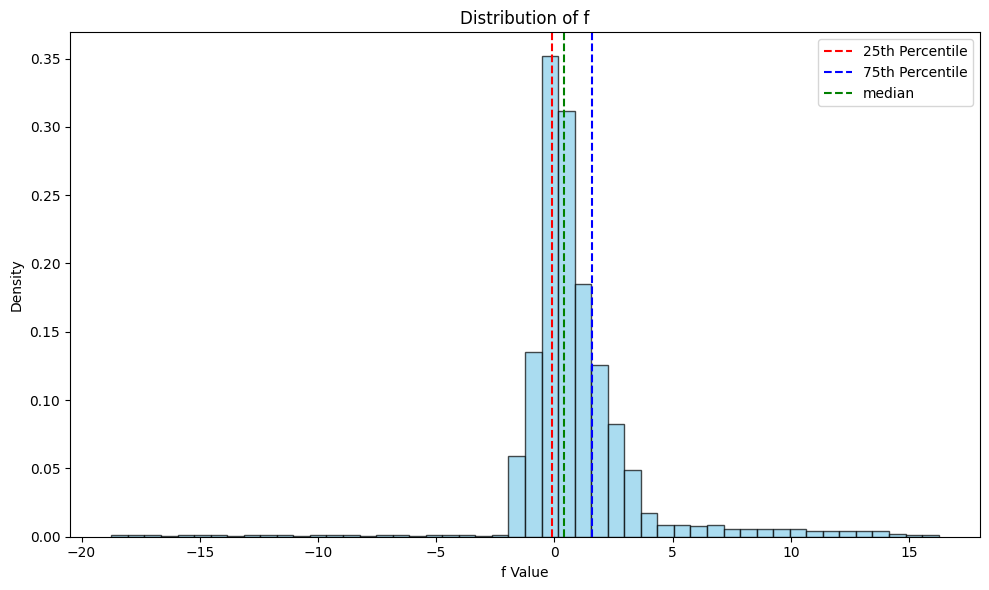

In [ ]:
plot_f_data('chebyshev')

25 quantile value: -0.5177460036401222, median value 0.16622785933378686, 75 quantile value 0.7458245320217405


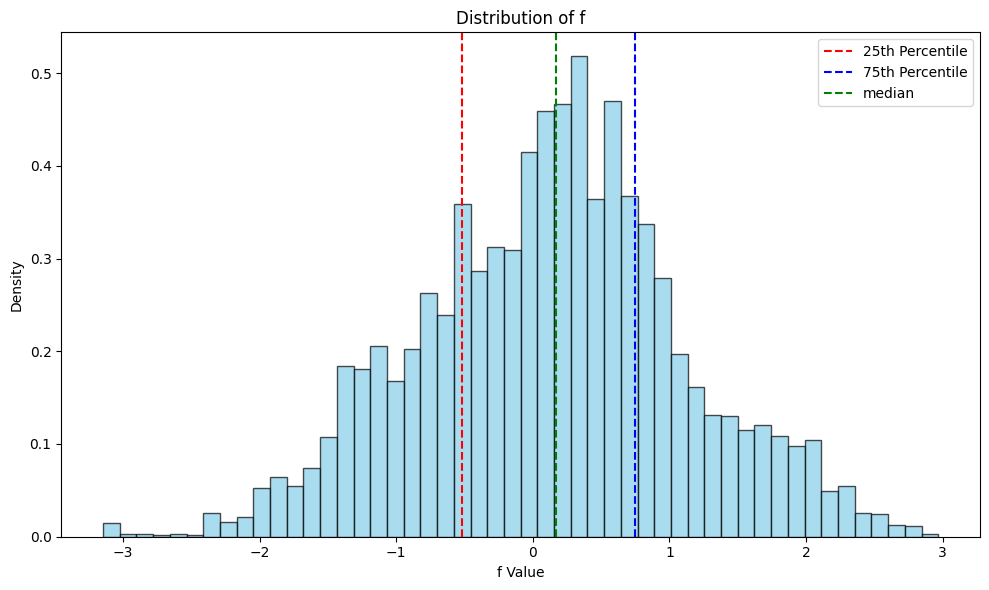

In [ ]:
plot_f_data('gaussian_process')

25 quantile value: -0.48590915498932574, median value 0.0, 75 quantile value 1.3722587573863763


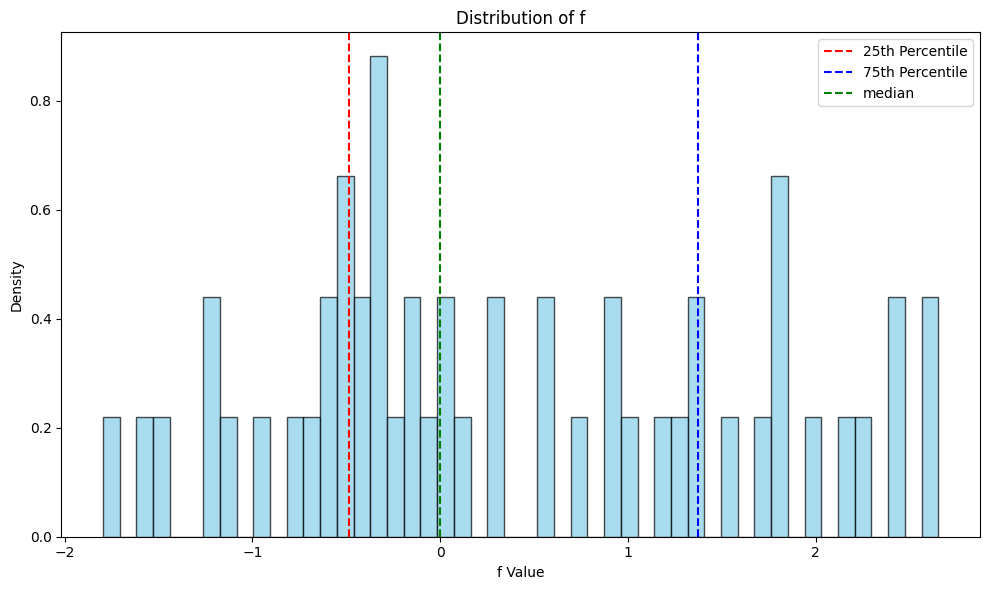

In [ ]:
plot_f_data('piecewise_linear')